# Baseline: logistic regression without rebalancing

Goal: a first reference model, trained on the imbalanced data

In [1]:
import sys
sys.path.append('..')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from src.config import SEED
from src.data import load_splits
from src.metrics import evaluate, confusion_rows

sns.set_theme(style='whitegrid')

data, y_train, y_test = load_splits()
data['salary']['X_train_s'].shape, data['no_salary']['X_train_s'].shape

((51416, 26), (51416, 25))

## always predict the most frequent class

In [2]:
dummy = DummyClassifier(strategy='most_frequent').fit(data['no_salary']['X_train_s'], y_train)
summary, _ = evaluate(y_test, dummy.predict(data['no_salary']['X_test_s']))
summary

{'accuracy': 0.31116297160637885, 'macro_f1': 0.09492732126965292}

## Logistic regression on both feature sets

Trained on the scaled data, no class weights, no resampling.

In [3]:
results, per_class, preds = {}, {}, {}
for name, d in data.items():
    model = LogisticRegression(max_iter=1000, random_state=SEED)
    model.fit(d['X_train_s'], y_train)
    preds[name] = model.predict(d['X_test_s'])
    results[name], per_class[name] = evaluate(y_test, preds[name])

pd.DataFrame(results).T.round(4)

,accuracy,macro_f1
salary,0.3784,0.2153
no_salary,0.3140,0.1948


## Per-class metrics

Accuracy hides what happens on the rare classes. Recall is the share of each class that is found, precision the share of the predictions of a class that are right.

In [4]:
for name, table in per_class.items():
    print(name)
    display(table.round(3))

salary


,precision,recall,f1,support
1,0.000,0.000,0.000,80
2,0.000,0.000,0.000,801
3,0.370,0.546,0.441,4000
4,0.318,0.113,0.167,3988
5,0.402,0.559,0.468,3986


no_salary


,precision,recall,f1,support
1,0.000,0.000,0.000,80
2,0.000,0.000,0.000,801
3,0.320,0.371,0.344,4000
4,0.311,0.311,0.311,3988
5,0.311,0.329,0.320,3986


In [5]:
pd.DataFrame({name: np.bincount(p, minlength=6)[1:] for name, p in preds.items()}, index=[1, 2, 3, 4, 5]).rename_axis('predicted class')

,salary,no_salary
predicted class,,
1,0,0
2,0,0
3,5899,4645
4,1422,3996
5,5534,4214


## Confusion matrices (normalized by row)

Each row is a true class and sums to 1: the diagonal is the recall.

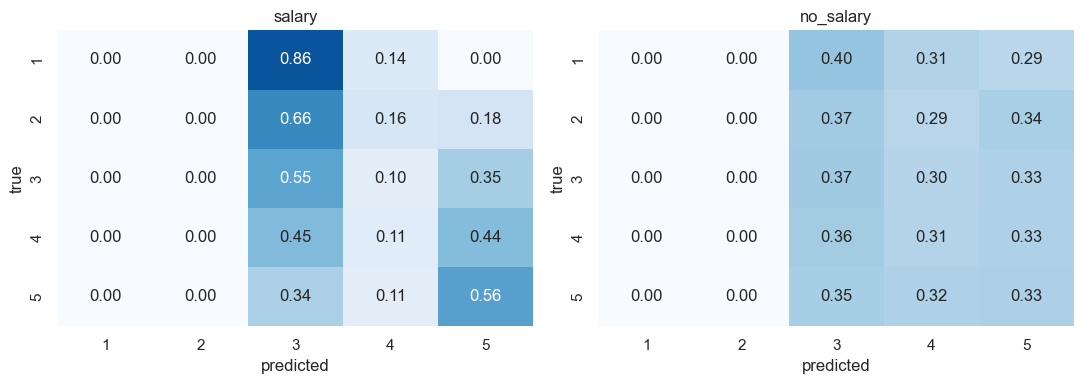

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, (name, p) in zip(axes, preds.items()):
    sns.heatmap(confusion_rows(y_test, p), annot=True, fmt='.2f', cmap='Blues', vmin=0, vmax=1, ax=ax, cbar=False)
    ax.set_title(name)
    ax.set_xlabel('predicted')
    ax.set_ylabel('true')
plt.tight_layout()
plt.show()

## Notes

- **Reference**: always predicting the most frequent class (score 3) gives an accuracy of about 0.31 and a macro F1 of about 0.09.
- **Results** (test set, 12,855 rows): with salary, accuracy ≈ 0.38 and macro F1 ≈ 0.215; without salary, accuracy ≈ 0.31 and macro F1 ≈ 0.195. Without salary the model is no better than the reference on accuracy.
- **Classes 1 and 2 are never predicted** (0 predictions out of 12,855, in both sets): precision, recall and F1 are exactly 0 for 881 test rows. The model minimizes the overall log-loss, and these two classes represent only 6.9 % of the rows, so ignoring them costs little. Accuracy hides this completely: 0.38 looks like a modest model, but it does not detect a single employee of score 1 or 2.
- **Without salary** the confusion matrix is almost flat: each true class is spread over predictions 3, 4 and 5 in roughly equal parts (0.29 to 0.40 per cell), and the predicted counts are balanced (4,645 / 3,996 / 4,214). The features carry no signal, in line with the EDA.
- **With salary** the model starts to separate: score 5 is found 56 % of the time (recall 0.56) and score 3 55 %, but score 4 only 11 %. Class 4 sits between 3 and 5 on the salary axis and is squeezed by a linear boundary. Low-score employees are all pushed to class 3 (86 % of the class 1 rows, 66 % of class 2): the model uses salary as an ordinal signal, but it has no way to output a class it never predicts.
- **Salary helps little here** (macro F1 0.195 → 0.215) although it determines the score almost exactly together with the job title: the relation is non-linear and depends on the job title, which a linear model without `Job_Title` cannot use.
- **Why accuracy is misleading**: it rewards predicting the three large classes and ignores the two rare ones. Macro F1 gives each class the same weight, so ignoring classes 1 and 2 caps it at 3/5 of the classes. That is why it is the main metric of the project.
- **Next**: commit 9 changes the training (undersampling, SMOTE, class weights) so that the model is forced to predict classes 1 and 2.